M at H = 0 : -5773.16908555852  A/m
Sample moment mi =  -0.00577316908555852 A m^2


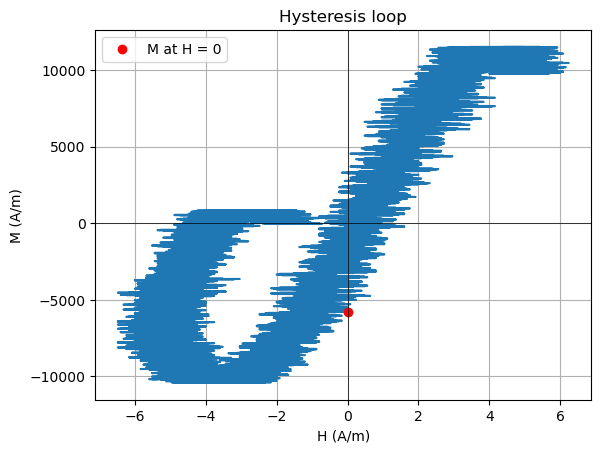

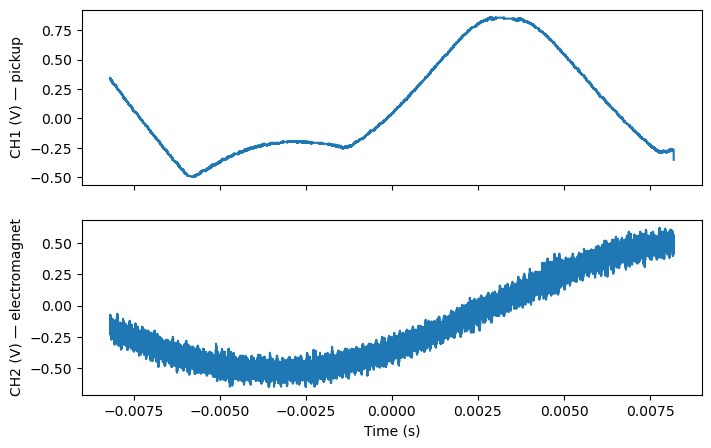

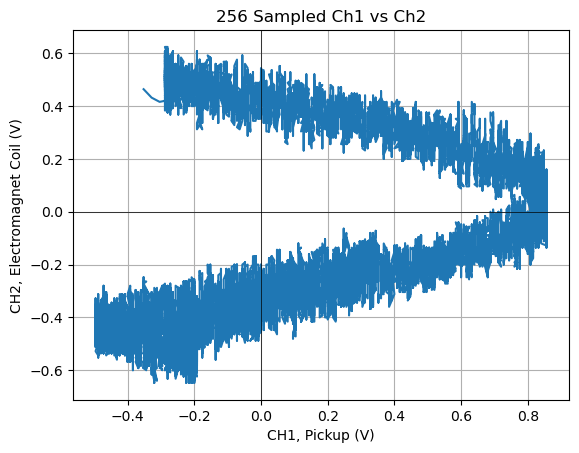

SDS00001.CSV


In [1]:
# This code is for signal processing for a magnetometer. 
# It aims to output the residual values of M and m_i where M = SUM(m_i) / V
# It is modified for the data collected on WEEK 9 25 September 2026
# It will take as input 1 csv file named SDS00001.CSV with the structure:
#
# Time(s) | CH1 (V) | CH2 (V) 
# 
# There are some junk columns to the left which will be omitted later
# 
# Where:
# - CH1 is the raw pickup coil voltage
# - CH2 is the raw voltage powering an electromagnet coil (measured accross a resistor in series)
# - Time is just the time associated with each signal
#
# If the CSV outputted isnt of this form, the csv should be changed.
#
# The whole simulation runs in SI units and will output hysterysis plots in SI units (scaled appropriately)
#
# The aim of this program is to create a hysterysis loop to extract atomic magnetic moment mi of sample
#
# The calculations follow the WEEK 9 tab or the SIGNAL FLOW tab in the google doc

'''
THE PLAN 
1. Import libraries required such as numpy, mapplotlib, scipy
2. Define Variables:
    - N_el: number of turns in electromagnet coil
    - Np: Number of turns in the pickup coil
    - l: length of the electromagnet coil
    - B(0): background magnetisation
    - R: Resistor value (the one in series with the electromagnet coil)
    - A: Area of the pickup coil (m^2)
    - mu0: vacuum magnetic permeability (SI units)
    - V: Volume of the sample
    
3. Import data from csv (in the same folder)

    - - - BEGIN H(t) COMPUTATUION (The electromagnet bit CH2) - - - 
4. Compute I(t) array from I(t) = V(t) / R
5. Compute B(t) array from B(t) = mu0 * I(t) * N / l
6. Compute H(t) array from H(t) = B(t) / mu0

    - - - BEGIN M(t) COMPUTATION (the pickup coil bit CH1) - - -
First we will compute additional array V -> dB/dt
7. Create an array dB/dt = - V(t) / (Np * A)
6. Call integrate function cumulative_simpsons rule for creating an additional array of B(t) - B(0)
7. Create an addittional array which represents B(t) = B(0) - int[V(t)dt]
8. Create final array M(t) = (B(t)/mu0) - H(t)
9. print mi to screen with mi = M(t) * Volume of sample

    - - - PLOT Hysterysis Loop - - -
    H(t) vs M(t)
'''
" ---- 1. Imports ------------------------------------------------------"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from scipy.integrate import cumulative_simpson 

" ---- 2. Parameters (edit these) --------------------------------------"
CSV_FILE = "SDS00001.CSV"     # same folder as the jupyter notebook file
N_el = 120                    # turns in the electromagnet coil
L = 0.120                     # length of electromagnet coil [m]  (120 mm)
R_pickup = 2.5                # internal impedance of pickup coil
R_el = 1.9                    # internal impedance of the electromagnet coil
R_added = 100                 # series resistor [ohm] (5 A * 1 ohm = 5 V on CH2; 25 W!)
R_tot = R_el                  # Treating the total electromagnet circuit resistance as series might be wrong, so will just use r_added
Np = 90                       # 90 turns in the pickup coil +- 5
A = 0.000346                  # pickup coil area [m^2]  (1 cm^2) (the Area of the pickup coil)
B0 =  0.00005733              # known static background field B(0) [T], Didn't take a measurement this time
V_sample = 1.0e-6             # sample volume [m^3]  (1 cm^3 = 1e-6 m^3)
mu0 = 4*np.pi*1E-7            # vacuum permeability 4PI E-7

" ---- 3. Import data --------------------------------------------------"
df = pd.read_csv(CSV_FILE, skiprows=2, header=None, usecols=[3, 4, 5],
                  names=["Time", "CH1", "CH2"])
t   = df["Time"].to_numpy(dtype=float)   # time [s]
ch1 = df["CH1"].to_numpy(dtype=float)    # pickup coil voltage [V]
ch2 = df["CH2"].to_numpy(dtype=float)    # electromagnet resistor voltage [V]
t, ch1, ch2 = t[:-4], ch1[:-4], ch2[:-4] # drop last 4 rows (artifact samples) 

" ---- BEGIN H(t) COMPUTATION (electromagnet, CH2) ---------------------"
# 4.
I = ch2 / R_added                        # [A] (just using the resistor in series)

# 5. Field at the centre of the electromagnet coil: B(t) = mu0 * I(t) * N / L"
B_el = mu0 * I * N_el / L              # [T]

# 6. Applied field: H(t) = B(t) / mu0"
H = B_el / mu0                         # [A/m]

" ---- BEGIN M(t) COMPUTATION (pickup coil, CH1) -----------------------"
# 7. Convert voltage to dB/dt: dB/dt = -V(t) / (Np * A)

dB_dt = -ch1 / (Np * A)                # [T/s]

# 8. Integrate dB/dt over time: gives B(t) - B(0)
#    (swap in cumulative_trapezoid if you want to compare the two methods)
#B_minus_B0 = cumulative_trapezoid(dB_dt, x=t, initial=0)   # [T]
B_minus_B0 = cumulative_simpson(dB_dt, x=t, initial=0)   # Comment line above and uncomment this to try it out

# 9. Add the background: B(t) = B(0) + [B(t) - B(0)]
B = B0 + B_minus_B0                    # [T]

# 10. Magnetisation: M(t) = B(t)/mu0 - H(t)
M = B / mu0 - H                        # [A/m]
M_corrected = -M                       # I think the pickup coil polarity is reversed so corrected value here

# 11. Moment of the sample: take M where the loop crosses H = 0
j = np.argmin(np.abs(H))               # finds the index of the abs value of H element that is closest to 0
M_at_H0 = -M[j]                        # [A/m] Finds the M of the same index (had to change sign to get hysteresis loop oriented correctly)
mi = M_at_H0 * V_sample                # [A m^2] mi individual magnetic moment
print("M at H = 0 :", M_at_H0, " A/m")
print("Sample moment mi = " ,mi, "A m^2")

" ---- PLOT Hysteresis loop: M vs H ------------------------------------"
plt.plot(H, M_corrected)                        # Had to change sign of M to get hysteresis loop oriented correctly
plt.plot(H[j], M_at_H0, "ro", label="M at H = 0")
plt.axhline(0, color="black", lw = 0.5)
plt.axvline(0, color="black", lw=0.5)
plt.xlabel("H (A/m)")
plt.ylabel("M (A/m)")
plt.title("Hysteresis loop")
plt.legend()
plt.grid()
plt.show()

" ---- PLOT Both Ch1 and Ch2 vs Time ------------------------------------"
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
ax[0].plot(t, ch1)
ax[0].set_ylabel("CH1 (V) — pickup")
ax[1].plot(t, ch2)
ax[1].set_ylabel("CH2 (V) — electromagnet")
ax[1].set_xlabel("Time (s)")
plt.show()

" ---- PLOT 256 Sampled Ch1 vs Ch2 ------------------------------------"
plt.plot(ch1, ch2)
plt.axhline(0, color="black", lw = 0.5)
plt.axvline(0, color="black", lw=0.5)
plt.xlabel("CH1, Pickup (V)")
plt.ylabel("CH2, Electromagnet Coil (V)")
plt.title("256 Sampled Ch1 vs Ch2")
plt.grid()
plt.show()


Something does not make sense to me about the last figure here. I don't see why plotting the averaged voltage values CH1 and CH2 against each other should produce a hysteresis loop. This might work if CH1 and CH2 were proportional to $M$ and $H$ respectively (assuming CH1 is pickup and CH2 is electromagnet). The voltage from CH1 is proportional to $\frac{dB}{dt}$ not M:

$$M(t) = \frac{B(0)-\frac{1}{N_p A}\int_0^t V(t)dt}{\mu0}-H(t)$$

Also, I think the x axis is nothing to do with $H$, it is the pickup voltage. 

Note that $\int \sin x = - \cos x$ which is propotional to sin so its not too crazy that we get a proportionality between this $\int_0^t V(t)dt$ and $M(t)$.

Flipping the last plot around:

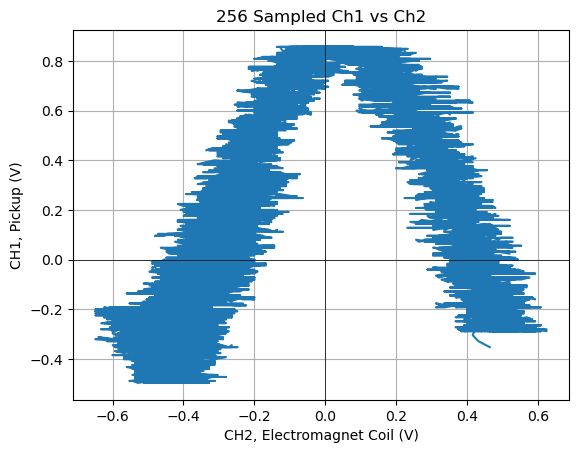

In [5]:
" ---- PLOT 256 Sampled Ch1 vs Ch2 ------------------------------------"
plt.plot(ch2, ch1)
plt.axhline(0, color="black", lw = 0.5)
plt.axvline(0, color="black", lw=0.5)
plt.ylabel("CH1, Pickup (V)")
plt.xlabel("CH2, Electromagnet Coil (V)")
plt.title("256 Sampled Ch1 vs Ch2")
plt.grid()
plt.show()


I'm not sure whats going on with our 

M at H = 0 : -19726.419038343593  A/m
Sample moment mi =  -0.01972641903834359 A m^2
The obtained plot is pretty similar with the solve_ivp approach:


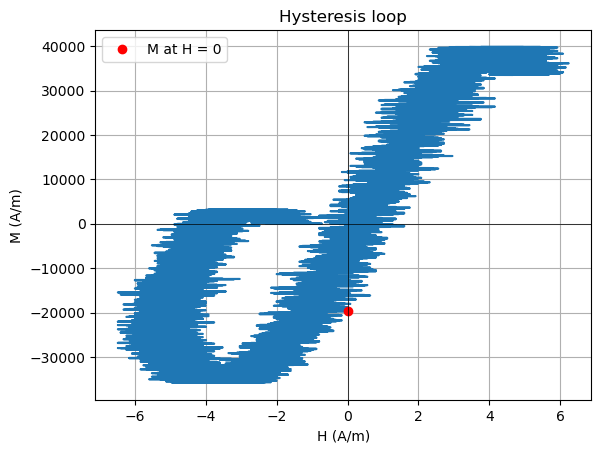

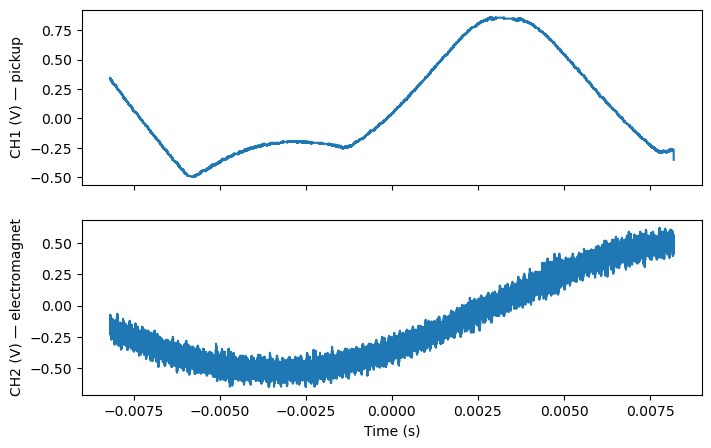

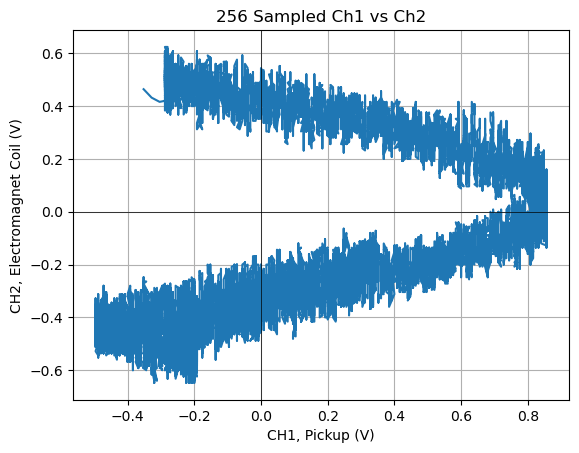

In [3]:
#Alternative Approach: Use solve_ivp instead of simpson or cumulative

# This code is for signal processing for a magnetometer. 

'''
solve_ivp

'''
" ---- 1. Imports ------------------------------------------------------"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from scipy.integrate import cumulative_simpson 
from scipy.interpolate import interp1d
from scipy.integrate import solve_ivp

" ---- 2. Parameters (edit these) --------------------------------------"
CSV_FILE = "SDS00001.CSV"     # same folder as the jupyter notebook file
N_el = 120                    # turns in the electromagnet coil
L = 0.120                     # length of electromagnet coil [m]  (120 mm)
R_pickup = 2.5                # internal impedance of pickup coil
R_el = 1.9                    # internal impedance of the electromagnet coil
R_added = 100                 # series resistor [ohm] (5 A * 1 ohm = 5 V on CH2; 25 W!)
R_tot = R_el + R_added        # Treating the total electromagnet circuit resistance as series might be wrong, so will just use r_added
Np = 366                      # 366 turns in the pickup coil +- 5
A = 1.0e-4                    # pickup coil area [m^2]  (1 cm^2)
B0 = 0                        # known static background field B(0) [T], Didn't take a measurement this time
V_sample = 1.0e-6             # sample volume [m^3]  (1 cm^3 = 1e-6 m^3)
mu0 = 4*np.pi*1E-7            # vacuum permeability 4PI E-7

" ---- 3. Import data --------------------------------------------------"
df = pd.read_csv(CSV_FILE, skiprows=2, header=None, usecols=[3, 4, 5],
                  names=["Time", "CH1", "CH2"])
t   = df["Time"].to_numpy(dtype=float)   # time [s]
ch1 = df["CH1"].to_numpy(dtype=float)    # pickup coil voltage [V]
ch2 = df["CH2"].to_numpy(dtype=float)    # electromagnet resistor voltage [V]
t, ch1, ch2 = t[:-4], ch1[:-4], ch2[:-4] # drop last 4 rows (artifact samples) 

" ---- BEGIN H(t) COMPUTATION (electromagnet, CH2) ---------------------"
# 4.
I = ch2 / R_added                        # [A] (just using the resistor in series)

# 5. Field at the centre of the electromagnet coil: B(t) = mu0 * I(t) * N / L"
B_el = mu0 * I * N_el / L              # [T]

# 6. Applied field: H(t) = B(t) / mu0"
H = B_el / mu0                         # [A/m]

" ---- BEGIN M(t) COMPUTATION (pickup coil, CH1) -----------------------"
# 7. Convert voltage to dB/dt: dB/dt = -V(t) / (Np * A)

dB_dt = -ch1 / (Np * A)                # [T/s]

# --- NEW ODE SOLVER METHOD (solve_ivp) ---
# Create an interpolation function so the ODE solver can read dB/dt at any exact timestamp 'time_val'
dB_dt_func = interp1d(t, dB_dt, kind='linear', fill_value="extrapolate")

# Define the differential equation: dB/dt = f(t, B)
def db_dt_ode(time_val, B_val):
    return dB_dt_func(time_val)

# Run the ODE solver over the full time span
# We set y0=[0] because B_minus_B0 starts at 0 at t[0]
# t_eval forces the solver to output values matching your exact experimental time array rows
solution = solve_ivp(db_dt_ode, t_span=(t[0], t[-1]), y0=[0], t_eval=t, method='RK45')

# Extract the integrated data array
B_minus_B0 = solution.y[0]             # [T]
# -----------------------------------------
# 9. Add the background: B(t) = B(0) + [B(t) - B(0)]
B = B0 + B_minus_B0                    # [T]

# 10. Magnetisation: M(t) = B(t)/mu0 - H(t)
M = B / mu0 - H                        # [A/m]
M_corrected = -M                       # I think the pickup coil polarity is reversed so corrected value here

# 11. Moment of the sample: take M where the loop crosses H = 0
j = np.argmin(np.abs(H))               # finds the index of the abs value of H element that is closest to 0
M_at_H0 = -M[j]                        # [A/m] Finds the M of the same index (had to change sign to get hysteresis loop oriented correctly)
mi = M_at_H0 * V_sample                # [A m^2] mi individual magnetic moment
print("M at H = 0 :", M_at_H0, " A/m")
print("Sample moment mi = " ,mi, "A m^2")
print("The obtained plot is pretty similar with the solve_ivp approach:")
" ---- PLOT Hysteresis loop: M vs H ------------------------------------"
plt.plot(H, M_corrected)                        # Had to change sign of M to get hysteresis loop oriented correctly
plt.plot(H[j], M_at_H0, "ro", label="M at H = 0")
plt.axhline(0, color="black", lw = 0.5)
plt.axvline(0, color="black", lw=0.5)
plt.xlabel("H (A/m)")
plt.ylabel("M (A/m)")
plt.title("Hysteresis loop")
plt.legend()
plt.grid()
plt.show()

" ---- PLOT Both Ch1 and Ch2 vs Time ------------------------------------"
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
ax[0].plot(t, ch1)
ax[0].set_ylabel("CH1 (V) — pickup")
ax[1].plot(t, ch2)
ax[1].set_ylabel("CH2 (V) — electromagnet")
ax[1].set_xlabel("Time (s)")
plt.show()

" ---- PLOT 256 Sampled Ch1 vs Ch2 ------------------------------------"
plt.plot(ch1, ch2)
plt.axhline(0, color="black", lw = 0.5)
plt.axvline(0, color="black", lw=0.5)
plt.xlabel("CH1, Pickup (V)")
plt.ylabel("CH2, Electromagnet Coil (V)")
plt.title("256 Sampled Ch1 vs Ch2")
plt.grid()
plt.show()
